# Repeated Cross-Validation of Individual Trust Signals

## Objective

Evaluate each repository signal individually for its ability to distinguish repositories labeled known-good from repositories labeled uncertain. Repeated stratified cross-validation provides a more complete view of performance than a single train/test split.

The primary metric is ROC-AUC. A score near 0.5 indicates little separation; higher scores indicate stronger separation in this dataset. Because logistic regression learns the direction of the relationship, a signal can be informative even when larger values are associated with the uncertain class.

## Evaluation design

- Use the shared `data/features.csv` dataset and signal columns listed in `data/manifest.json`.
- Keep each signal separate: fit one logistic-regression model per signal.
- Use 5-fold stratified cross-validation, repeated 10 times with different random seeds.
- Fit median imputation and standardization inside each training fold to prevent test-fold information from leaking into preprocessing.
- For each repeat, combine the held-out predictions from its five folds and calculate one ROC-AUC. This produces 10 AUC values per signal.
- Compare signals by their mean, standard deviation, minimum, maximum, and the proportion of repeats with AUC at least 0.6.

The repeat-level standard deviation is a descriptive measure of split sensitivity, not a confidence interval. Repeated CV reuses the same repositories, so the 10 AUC values are not independent estimates.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Allow the notebook to run with the working directory set to either the repo root or notebooks/.
ROOT_DIR = Path.cwd()
if not (ROOT_DIR / "data" / "features.csv").exists():
    ROOT_DIR = ROOT_DIR.parent

DATA_DIR = ROOT_DIR / "data"

with (DATA_DIR / "manifest.json").open(encoding="utf-8") as file:
    manifest = json.load(file)

signal_columns = manifest["signal_columns"]
data = pd.read_csv(DATA_DIR / "features.csv")

X = data[signal_columns].astype(float)
y = data["target_label"].astype(int)

if y.nunique() != 2:
    raise ValueError("ROC-AUC evaluation requires both target classes.")

n_splits = 5
n_repeats = 10
random_seed = 42

cv = RepeatedStratifiedKFold(
    n_splits=n_splits,
    n_repeats=n_repeats,
    random_state=random_seed,
)

# Generate the same folds for every signal, so their comparisons use identical splits.
splits = list(cv.split(X, y))

pipeline = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000, random_state=random_seed)),
    ]
)

print(f"Repositories: {len(data)}")
print(f"Signals evaluated: {len(signal_columns)}")
print(f"Known-good: {(y == 1).sum()}")
print(f"Uncertain: {(y == 0).sum()}")
print(f"Evaluation: {n_splits}-fold CV × {n_repeats} repeats")

Repositories: 106
Signals evaluated: 20
Known-good: 82
Uncertain: 24
Evaluation: 5-fold CV × 10 repeats


C:\Users\nehak\AppData\Local\Temp\ipykernel_15568\3614562855.py:93: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  boxplots = ax_distribution.boxplot(
C:\Users\nehak\AppData\Local\Temp\ipykernel_15568\3614562855.py:281: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax_spread.boxplot(


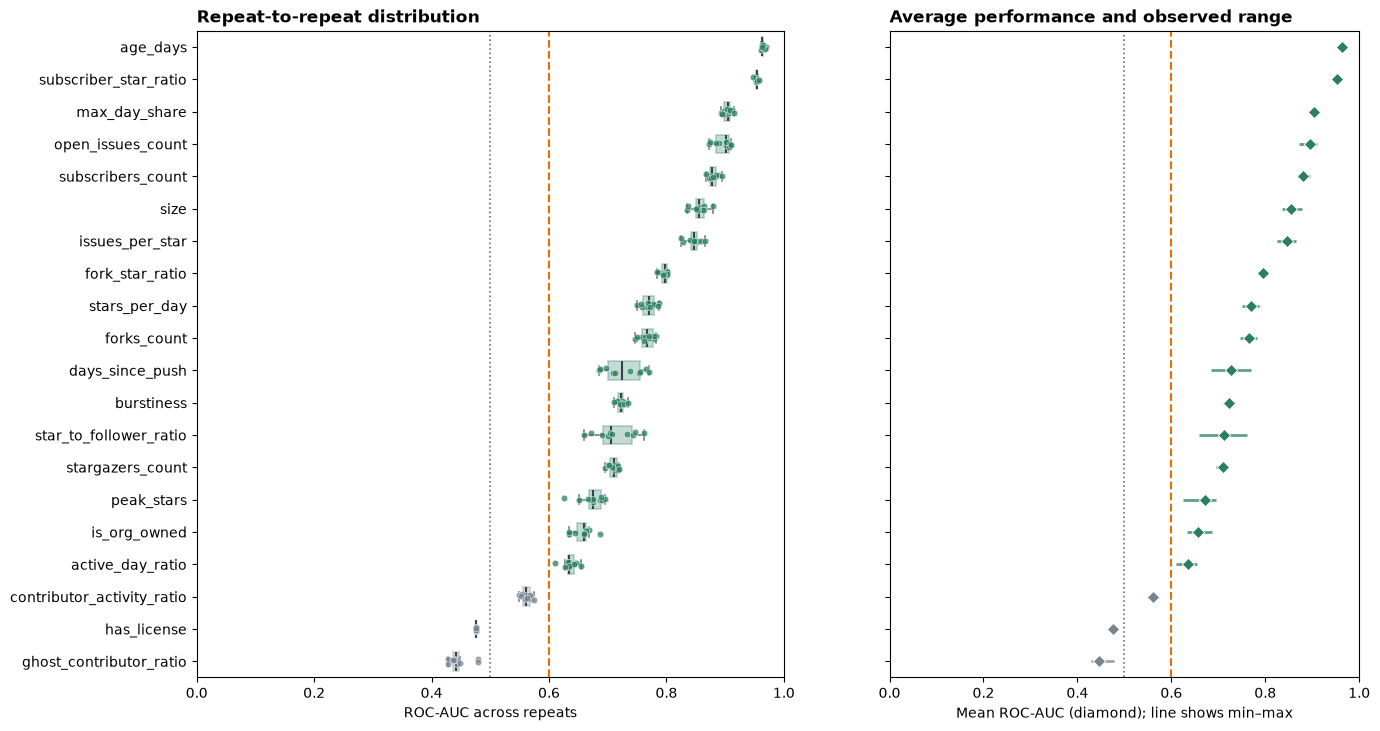

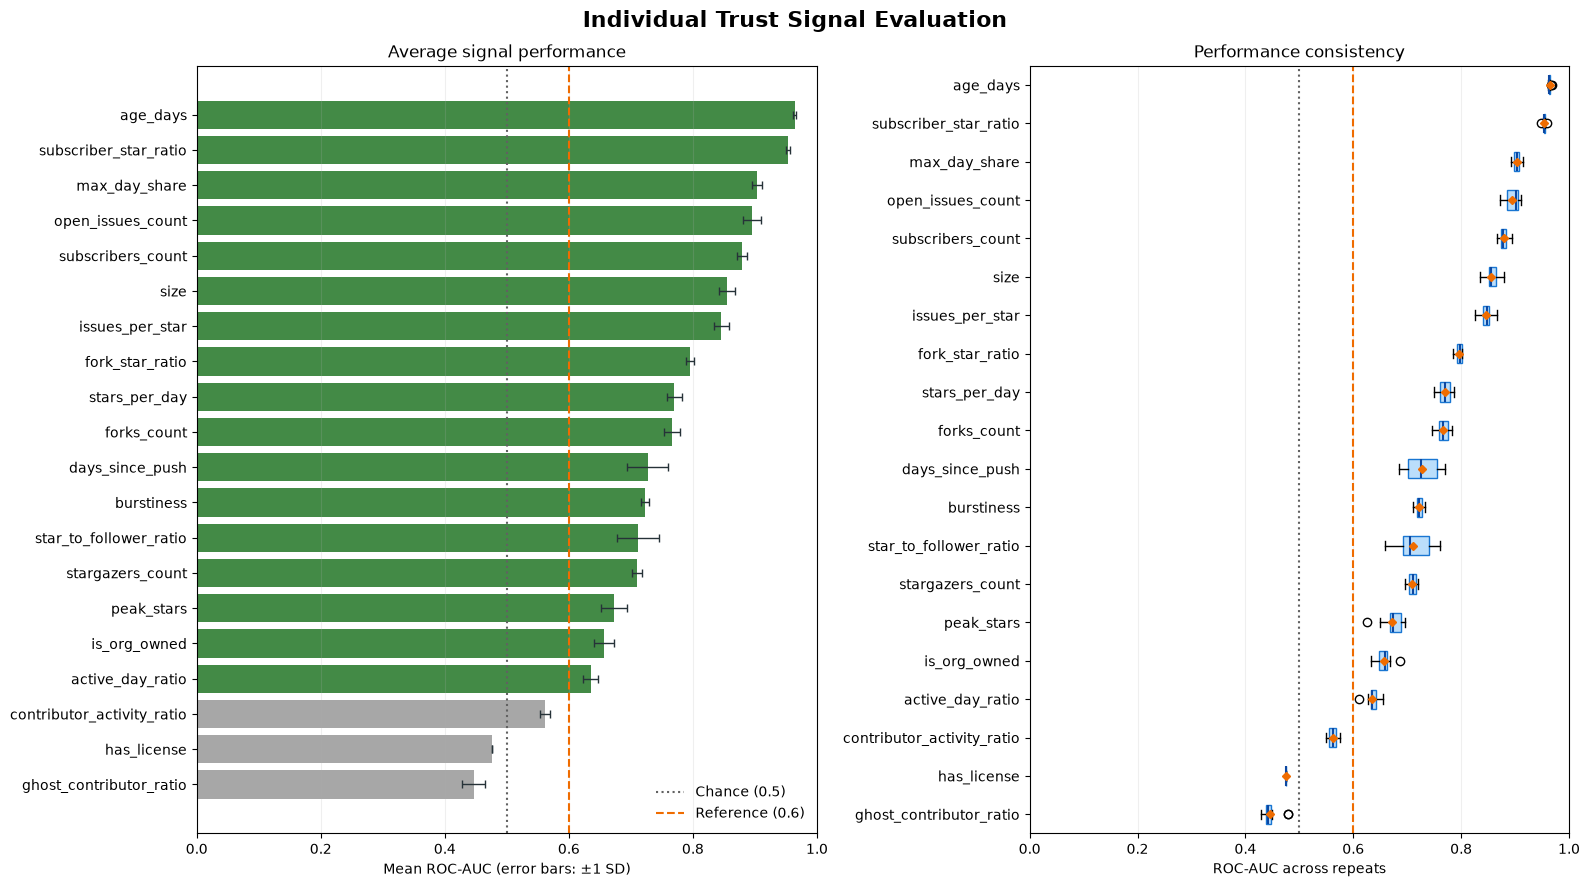

signal,mean_roc_auc,std_roc_auc,repeats_at_least_0.6,observation
age_days,0.964,0.002,100%,Promising; relatively consistent
subscriber_star_ratio,0.954,0.003,100%,Promising; relatively consistent
max_day_share,0.903,0.007,100%,Promising; relatively consistent
open_issues_count,0.895,0.014,100%,Promising; relatively consistent
subscribers_count,0.879,0.008,100%,Promising; relatively consistent
size,0.855,0.013,100%,Promising; relatively consistent
issues_per_star,0.846,0.013,100%,Promising; relatively consistent
fork_star_ratio,0.796,0.007,100%,Promising; relatively consistent
stars_per_day,0.770,0.012,100%,Promising; relatively consistent
forks_count,0.766,0.013,100%,Promising; relatively consistent


Full results saved to c:\Users\nehak\OneDrive\Documents\GitHub\Microsoft-3A-github-repo-trust-signals\data\signal_cv_results.csv


In [10]:
repeat_rows = []

for signal in signal_columns:
    signal_values = X[[signal]]

    for repeat in range(n_repeats):
        repeat_predictions = np.full(len(data), np.nan)

        first_split = repeat * n_splits
        repeat_splits = splits[first_split : first_split + n_splits]

        for train_indices, test_indices in repeat_splits:
            pipeline.fit(
                signal_values.iloc[train_indices],
                y.iloc[train_indices],
            )
            repeat_predictions[test_indices] = pipeline.predict_proba(
                signal_values.iloc[test_indices]
            )[:, 1]

        if np.isnan(repeat_predictions).any():
            raise RuntimeError(f"Some repositories did not receive a prediction for {signal}.")

        repeat_rows.append(
            {
                "signal": signal,
                "repeat": repeat + 1,
                "roc_auc": roc_auc_score(y, repeat_predictions),
            }
        )

repeat_results = pd.DataFrame(repeat_rows)

summary_rows = []

for signal, group in repeat_results.groupby("signal"):
    scores = group["roc_auc"]
    mean_auc = scores.mean()
    std_auc = scores.std(ddof=1)

    if mean_auc >= 0.6 and std_auc <= 0.05:
        observation = "Promising average; relatively consistent across repeats"
    elif mean_auc >= 0.6:
        observation = "Promising average; performance varies across repeats"
    elif mean_auc >= 0.55:
        observation = "Borderline; inspect performance and signal limitations"
    else:
        observation = "Weak or near chance on this dataset"

    summary_rows.append(
        {
            "signal": signal,
            "mean_roc_auc": mean_auc,
            "std_roc_auc": std_auc,
            "min_roc_auc": scores.min(),
            "max_roc_auc": scores.max(),
            "repeats_at_least_0.6": (scores >= 0.6).mean(),
            "observation": observation,
        }
    )

results = (
    pd.DataFrame(summary_rows)
    .sort_values("mean_roc_auc", ascending=False)
    .reset_index(drop=True)
)

results.to_csv(DATA_DIR / "signal_cv_results.csv", index=False)

# Signals are colored by their average performance and repeat-to-repeat consistency.
def signal_color(row):
    if row["mean_roc_auc"] >= 0.6 and row["std_roc_auc"] <= 0.05:
        return "#2a7f62"
    if row["mean_roc_auc"] >= 0.6:
        return "#d49a28"
    return "#788391"

colors = [signal_color(row) for _, row in results.iterrows()]
positions = np.arange(1, len(results) + 1)
score_groups = [
    repeat_results.loc[repeat_results["signal"] == signal, "roc_auc"].to_numpy()
    for signal in results["signal"]
]

fig, (ax_distribution, ax_range) = plt.subplots(
    ncols=2,
    figsize=(15, max(8, 0.42 * len(results))),
    sharey=True,
    gridspec_kw={"width_ratios": [1.25, 1]},
)

# Left: show the distribution of the 10 repeat-level AUC scores per signal.
boxplots = ax_distribution.boxplot(
    score_groups,
    positions=positions,
    vert=False,
    widths=0.58,
    patch_artist=True,
    showfliers=False,
)

for box, color in zip(boxplots["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.28)
    box.set_edgecolor(color)
    box.set_linewidth(1.4)

for element in ("whiskers", "caps"):
    for artist in boxplots[element]:
        artist.set_color("#667085")
        artist.set_linewidth(1.1)

for median in boxplots["medians"]:
    median.set_color("#344054")
    median.set_linewidth(1.5)

rng = np.random.default_rng(42)
for position, scores, color in zip(positions, score_groups, colors):
    jitter = rng.uniform(-0.09, 0.09, size=len(scores))
    ax_distribution.scatter(
        scores,
        position + jitter,
        s=22,
        color=color,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.4,
        zorder=3,
    )

ax_distribution.set_yticks(positions, results["signal"])
ax_distribution.invert_yaxis()
ax_distribution.set_xlim(0, 1)
ax_distribution.set_xlabel("ROC-AUC across repeats")
ax_distribution.set_title("Repeat-to-repeat distribution", loc="left", fontweight="bold")

# Right: compare the mean AUC and the observed minimum-to-maximum range.
for position, (_, row), color in zip(positions, results.iterrows(), colors):
    ax_range.hlines(
        position,
        row["min_roc_auc"],
        row["max_roc_auc"],
        color=color,
        linewidth=2,
        alpha=0.75,
    )
    ax_range.scatter(
        row["mean_roc_auc"],
        position,
        marker="D",
        s=40,
        color=color,
        edgecolors="white",
        linewidths=0.7,
        zorder=3,
    )

ax_range.set_xlim(0, 1)
ax_range.set_xlabel("Mean ROC-AUC (diamond); line shows min–max")
ax_range.set_title("Average performance and observed range", loc="left", fontweight="bold")

for ax in (ax_distribution, ax_range):
    ax.axvline(0.5, color="#667085", linestyle=":", linewidth=1.2)
    ax.axvline(0.6, color="#ef6c00", linestyle="--", linewidth=1.5, label="Reference (0.6)")

repeat_rows = []

for signal in signal_columns:
    signal_values = X[[signal]]

    for repeat in range(n_repeats):
        repeat_predictions = np.full(len(data), np.nan)

        first_split = repeat * n_splits
        repeat_splits = splits[first_split : first_split + n_splits]

        for train_indices, test_indices in repeat_splits:
            pipeline.fit(
                signal_values.iloc[train_indices],
                y.iloc[train_indices],
            )
            repeat_predictions[test_indices] = pipeline.predict_proba(
                signal_values.iloc[test_indices]
            )[:, 1]

        if np.isnan(repeat_predictions).any():
            raise RuntimeError(
                f"Some repositories did not receive a prediction for {signal}."
            )

        repeat_rows.append(
            {
                "signal": signal,
                "repeat": repeat + 1,
                "roc_auc": roc_auc_score(y, repeat_predictions),
            }
        )

repeat_results = pd.DataFrame(repeat_rows)

summary_rows = []

for signal, group in repeat_results.groupby("signal"):
    scores = group["roc_auc"]
    mean_auc = scores.mean()
    std_auc = scores.std(ddof=1)

    if mean_auc >= 0.6 and std_auc <= 0.05:
        observation = "Promising; relatively consistent"
    elif mean_auc >= 0.6:
        observation = "Promising; varies across repeats"
    elif mean_auc >= 0.55:
        observation = "Borderline; review limitations"
    else:
        observation = "Weak or near chance"

    summary_rows.append(
        {
            "signal": signal,
            "mean_roc_auc": mean_auc,
            "std_roc_auc": std_auc,
            "min_roc_auc": scores.min(),
            "max_roc_auc": scores.max(),
            "repeats_at_least_0.6": (scores >= 0.6).mean(),
            "observation": observation,
        }
    )

results = (
    pd.DataFrame(summary_rows)
    .sort_values("mean_roc_auc", ascending=False)
    .reset_index(drop=True)
)

results.to_csv(DATA_DIR / "signal_cv_results.csv", index=False)

# Plot mean performance with one standard deviation across repeats.
plot_results = results.sort_values("mean_roc_auc", ascending=True)
colors = [
    "#2e7d32" if auc >= 0.6 else "#9e9e9e"
    for auc in plot_results["mean_roc_auc"]
]

fig, (ax_mean, ax_spread) = plt.subplots(
    ncols=2,
    figsize=(16, 9),
    gridspec_kw={"width_ratios": [1.15, 1]},
)

positions = np.arange(len(plot_results))

ax_mean.barh(
    positions,
    plot_results["mean_roc_auc"],
    color=colors,
    alpha=0.9,
)
ax_mean.errorbar(
    plot_results["mean_roc_auc"],
    positions,
    xerr=plot_results["std_roc_auc"],
    fmt="none",
    ecolor="#263238",
    capsize=3,
    linewidth=1,
)
ax_mean.axvline(0.5, color="#616161", linestyle=":", linewidth=1.5, label="Chance (0.5)")
ax_mean.axvline(0.6, color="#ef6c00", linestyle="--", linewidth=1.5, label="Reference (0.6)")
ax_mean.set_yticks(positions, plot_results["signal"])
ax_mean.set_xlim(0, 1)
ax_mean.set_xlabel("Mean ROC-AUC (error bars: ±1 SD)")
ax_mean.set_title("Average signal performance")
ax_mean.grid(axis="x", alpha=0.2)
ax_mean.legend(loc="lower right", frameon=False)

scores_by_signal = [
    repeat_results.loc[repeat_results["signal"] == signal, "roc_auc"].to_numpy()
    for signal in plot_results["signal"]
]

ax_spread.boxplot(
    scores_by_signal,
    vert=False,
    tick_labels=plot_results["signal"],
    showmeans=True,
    patch_artist=True,
    boxprops={"facecolor": "#bbdefb", "edgecolor": "#1976d2"},
    medianprops={"color": "#0d47a1", "linewidth": 1.5},
    meanprops={
        "marker": "D",
        "markerfacecolor": "#ef6c00",
        "markeredgecolor": "#ef6c00",
        "markersize": 4,
    },
)
ax_spread.axvline(0.5, color="#616161", linestyle=":", linewidth=1.5)
ax_spread.axvline(0.6, color="#ef6c00", linestyle="--", linewidth=1.5)
ax_spread.set_xlim(0, 1)
ax_spread.set_xlabel("ROC-AUC across repeats")
ax_spread.set_title("Performance consistency")
ax_spread.grid(axis="x", alpha=0.2)

fig.suptitle(
    "Individual Trust Signal Evaluation",
    fontsize=16,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

# Keep the visible table concise; the CSV contains every reported statistic.
display_columns = [
    "signal",
    "mean_roc_auc",
    "std_roc_auc",
    "repeats_at_least_0.6",
    "observation",
]
display(
    results[display_columns].style
    .format(
        {
            "mean_roc_auc": "{:.3f}",
            "std_roc_auc": "{:.3f}",
            "repeats_at_least_0.6": "{:.0%}",
        }
    )
    .background_gradient(
        subset=["mean_roc_auc"],
        cmap="RdYlGn",
        vmin=0.5,
        vmax=1.0,
    )
    .hide(axis="index")
    .set_caption("Signal comparison across repeated cross-validation")
)

print(f"Full results saved to {DATA_DIR / 'signal_cv_results.csv'}")